# 02 — Tiền xử lý: kiểm tra đầu ra và mô tả quy trình

Notebook này **không tạo dữ liệu**. Dữ liệu được tạo bằng lệnh
`PYTHONPATH=src .venv/Scripts/python -m quickdraw.prepare`, đọc ở đây để:
(1) kiểm tra việc chia tập, (2) minh hoạ từng bước biến đổi, (3) đo tốc độ nạp dữ liệu.
Mỗi quyết định đều dựa trên một phát hiện trong `01_eda.ipynb` (mục 13).

In [1]:
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from quickdraw.dataset import QuickDrawSplit, RasterView, SequenceView, load_seq_stats
from quickdraw.prepare import PROCESSED_DIR, REPORT_DIR, SPLITS
from quickdraw.transforms import (EVAL_FRACS, RESAMPLE_STEP, AugmentConfig, augment, downsample,
                                  normalize, prefix, rasterize, resample_uniform, to_sequence)

FIG = REPORT_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})


def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


def show_xy(ax, pts, end, title=None, canvas=255):
    for s in np.split(np.asarray(pts, float), np.flatnonzero(end)[:-1] + 1):
        ax.plot(s[:, 0], s[:, 1], "k-" if len(s) > 1 else "k.", lw=1, ms=3)
    ax.set_xlim(-5, canvas + 5)
    ax.set_ylim(canvas + 5, -5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=8)


manifest = json.loads((PROCESSED_DIR / "manifest.json").read_text())
ds = {s: QuickDrawSplit(s) for s in SPLITS}
print({k: manifest[k] for k in ("split_version", "seed", "rows_in_source", "rows_dropped",
                                "rows_per_split", "train_per_class_min_max", "split_digest")})

{'split_version': 'v1', 'seed': 42, 'rows_in_source': 3000000, 'rows_dropped': 99, 'rows_per_split': {'train': 2399901, 'val': 300000, 'test': 300000}, 'train_per_class_min_max': [23994, 24000], 'split_digest': '1aa4e15a1b8ce88d8b36a82a98f0e3cba022b805a1b36bcc14bbdcfc7bc96fe5'}


## 1. Làm sạch và chia tập

* **Loại:** chỉ những hình có dữ liệu nét giống hệt nhau nhưng mang nhãn của nhiều lớp
  (99 hàng, đều là đoạn thẳng 2 điểm). Các hình còn lại được giữ và gắn cờ: `tiny`
  (≤ 3 điểm), `dots_only`, `severe_nonconform` (lệch chuẩn hoá > 2 px), `recognized`.
* **Chia tập:** với từng lớp (theo thứ tự tên), xáo các *nhóm hình giống hệt nhau* bằng
  `numpy.random.default_rng(42)`. 3.000 hình đầu vào val, 3.000 tiếp theo vào test, phần
  còn lại vào train. Nhờ vậy hai bản sao của một hình không thể nằm ở hai split khác
  nhau, và val/test cân bằng tuyệt đối giữa các lớp.
* **Không chia theo người vẽ**, vì QuickDraw không công bố user id. Đây là một giới hạn:
  cùng một người có thể có hình ở cả train và test.
* `split_digest` là sha256 của các dòng `key_id,split` đã sắp xếp: hai máy tạo ra cùng
  một cách chia khi và chỉ khi digest trùng nhau.

In [2]:
rows = []
for s, d in ds.items():
    m = d.meta
    cc = m["countrycode"].fillna("<missing>")
    rows.append({
        "split": s, "n": len(m), "classes": m["word"].nunique(),
        "per_class_min": m["word"].value_counts().min(), "per_class_max": m["word"].value_counts().max(),
        "recognized": m["recognized"].mean(), "tiny": m["tiny"].mean(), "dots_only": m["dots_only"].mean(),
        "severe_nonconform": m["severe_nonconform"].mean(), "US_share": (cc == "US").mean(),
        "n_countries": cc.nunique(), "n_points_median": m["n_points"].median(),
        "n_points_p99": m["n_points"].quantile(.99), "n_strokes_median": m["n_strokes"].median(),
    })
summary = pd.DataFrame(rows).set_index("split")
summary.to_csv(REPORT_DIR / "split_summary.csv")
summary.T.astype(object).map(lambda v: f"{v:,.0f}" if abs(v) >= 10 else f"{v:.4f}")

split,train,val,test
n,"2,399,901","300,000","300,000"
classes,100,100,100
per_class_min,"23,994","3,000","3,000"
per_class_max,"24,000","3,000","3,000"
recognized,0.9176,0.9177,0.9169
tiny,0.0003,0.0002,0.0002
dots_only,0.0000,0.0000,0.0000
severe_nonconform,0.0085,0.0085,0.0088
US_share,0.4427,0.4421,0.4422
n_countries,207,185,191


Các split giống nhau về mọi thống kê (tỉ lệ recognized, các cờ, quốc gia, độ dài),
đúng như kỳ vọng của một phép chia ngẫu nhiên phân tầng theo lớp. Tỉ lệ recognized theo
lớp ở từng split được so sánh dưới đây.

In [3]:
rec = pd.DataFrame({s: d.meta.groupby("word")["recognized"].mean() for s, d in ds.items()})
print("Chênh lệch tuyệt đối lớn nhất của recognized rate theo lớp, val/test so với train:")
print((rec[["val", "test"]].sub(rec["train"], axis=0)).abs().max().round(4).to_dict())

Chênh lệch tuyệt đối lớn nhất của recognized rate theo lớp, val/test so với train:
{'val': 0.0119, 'test': 0.0166}


## 2. Định dạng lưu trữ

Mỗi split gồm 4 file trong `dataset/processed/`. Toạ độ được lưu **nguyên bản** (uint8,
không chuẩn hoá) để không mất thông tin; mọi phép biến đổi chạy lúc nạp dữ liệu.

| File | Nội dung |
|---|---|
| `{split}_xy.npy` | uint8 `(P, 2)`: toạ độ x, y của mọi điểm, nối liên tiếp |
| `{split}_end.npy` | bool `(P,)`: True ở điểm cuối của mỗi nét |
| `{split}_offsets.npy` | int64 `(N + 1,)`: hình i là các điểm `offsets[i]:offsets[i+1]` |
| `{split}_meta.parquet` | `key_id, row, label, word, recognized, countrycode, n_points, n_strokes`, các cờ |

In [4]:
for s, d in ds.items():
    size = sum((PROCESSED_DIR / f"{s}_{k}").stat().st_size for k in ("xy.npy", "end.npy", "offsets.npy", "meta.parquet"))
    print(f"{s:5s}: {len(d):>9,} hình, {len(d.xy):>11,} điểm, {size / 2**20:7.1f} MiB")

train: 2,399,901 hình, 112,718,239 điểm,   372.9 MiB
val  :   300,000 hình,  14,090,323 điểm,    46.9 MiB
test :   300,000 hình,  14,101,473 điểm,    47.0 MiB


## 3. Các bước biến đổi

Thứ tự: **prefix (toạ độ gốc) → augment (chỉ khi train) → chuẩn hoá → raster hoặc chuỗi.**

1. **Prefix theo độ dài mực** (`transforms.prefix`, `mode="ink"`): giữ các điểm cho tới
   khi đạt `frac` tổng độ dài mực, nội suy điểm cuối. Không bao giờ rỗng. Hình chỉ gồm
   chấm (không có mực) thì cắt theo số điểm. Có sẵn `mode="strokes_ceil"` để tái lập
   định nghĩa lúc chọn lớp.
2. **Augment** (`AugmentConfig`): xoay ±10°, scale riêng từng trục 0,9–1,1, shear ±0,1.
   Không lật (EDA chưa kiểm tra tính đối xứng của các lớp).
3. **Chuẩn hoá** (`normalize`): dời về góc trên-trái, scale cạnh dài về 255, giữ tỉ lệ.
   Vì chạy *sau* bước prefix nên prefix được scale theo khung của chính nó. Bước này giấu độ
   lớn của prefix nhưng **không chặn hết rò rỉ tỉ lệ** (mục 6).
4. **Raster** (`rasterize`): 64×64 uint8, căn giữa, lề 2 px, nét dày 2 px có antialias, chấm
   được vẽ thành điểm. Tuỳ chọn `order_encoding` mã hoá thứ tự nét bằng cường độ.
5. **Chuỗi** (`to_sequence`): stroke-3 `(dx, dy, pen_lift)`, tối đa 256 điểm. Hình dài hơn
   được **giảm mẫu** (giữ đầu/cuối mọi nét và các điểm cách đều) thay vì cắt cụt. dx, dy
   chia cho độ lệch chuẩn **fit trên train** (`seq_stats.json`).
6. **Lấy mẫu lại đều** (`resample_uniform`, tuỳ chọn `resample_step` của `SequenceView`): lấy
   điểm giữa các cung đều nhau trên mỗi nét, trước khi tạo chuỗi. Loại lưới toạ độ và mật độ
   điểm (mục 6). Thang độ lệch chuẩn riêng, fit trên train, nằm trong
   `src/quickdraw/seq_stats_resampled.json`.

seq_stats.json: {'fitted_on': 'train', 'n_deltas': 110318338, 'delta_mean': [1.014687, 0.688227], 'delta_std': [33.659789, 31.713892], 'note': 'deltas between consecutive points of full drawings normalised to long side 255'}


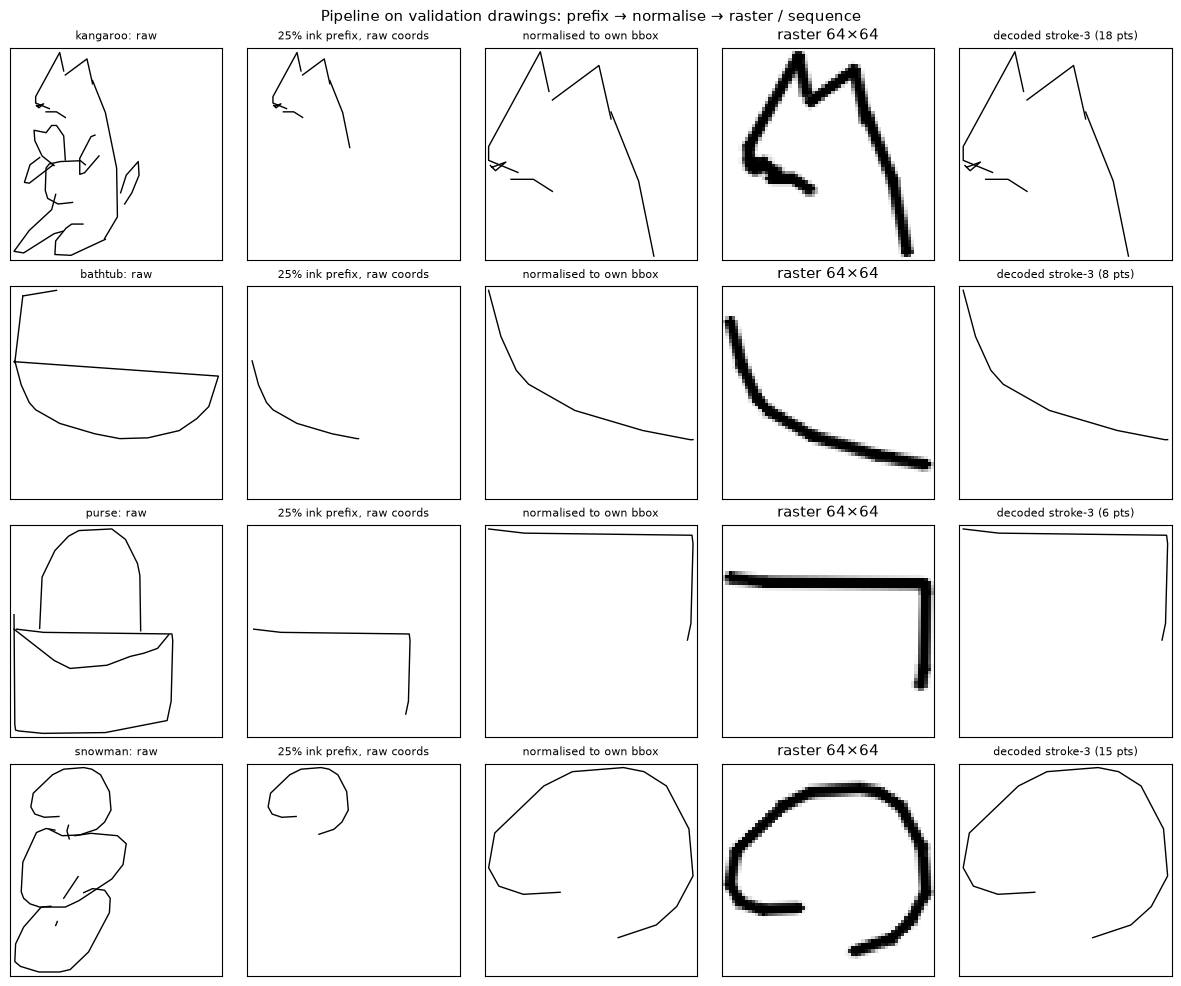

In [5]:
std = load_seq_stats()
print("seq_stats.json:", json.loads((PROCESSED_DIR / "seq_stats.json").read_text()))

val = ds["val"]
rng = np.random.default_rng(SEED)
pick = rng.choice(len(val), 4, replace=False)
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for r, i in enumerate(pick):
    pts, end, label = val[i]
    p, e = prefix(pts, end, 0.25)
    n = normalize(p)
    seq, k = to_sequence(n, e, 256, std)
    rec = np.cumsum(seq[:k, :2] * std, axis=0)
    show_xy(axes[r, 0], pts, end, f"{val.meta['word'].iloc[i]}: raw")
    show_xy(axes[r, 1], p, e, "25% ink prefix, raw coords")
    show_xy(axes[r, 2], n, e, "normalised to own bbox")
    axes[r, 3].imshow(rasterize(n, e, 64), cmap="gray_r")
    axes[r, 3].set(xticks=[], yticks=[], title="raster 64×64")
    show_xy(axes[r, 4], rec, seq[:k, 2].astype(bool), f"decoded stroke-3 ({k} pts)")
fig.suptitle("Pipeline on validation drawings: prefix → normalise → raster / sequence")
plt.tight_layout()
savefig("pipeline_steps")
plt.show()

### Prefix ở các mức đánh giá cố định

Val/test luôn được đánh giá ở `EVAL_FRACS` = 10/25/50/75/100%, không augment, nên mọi
model nhìn thấy đúng cùng một dữ liệu. Không cần lưu sẵn các bản prefix vì
`prefix()` là hàm tất định.

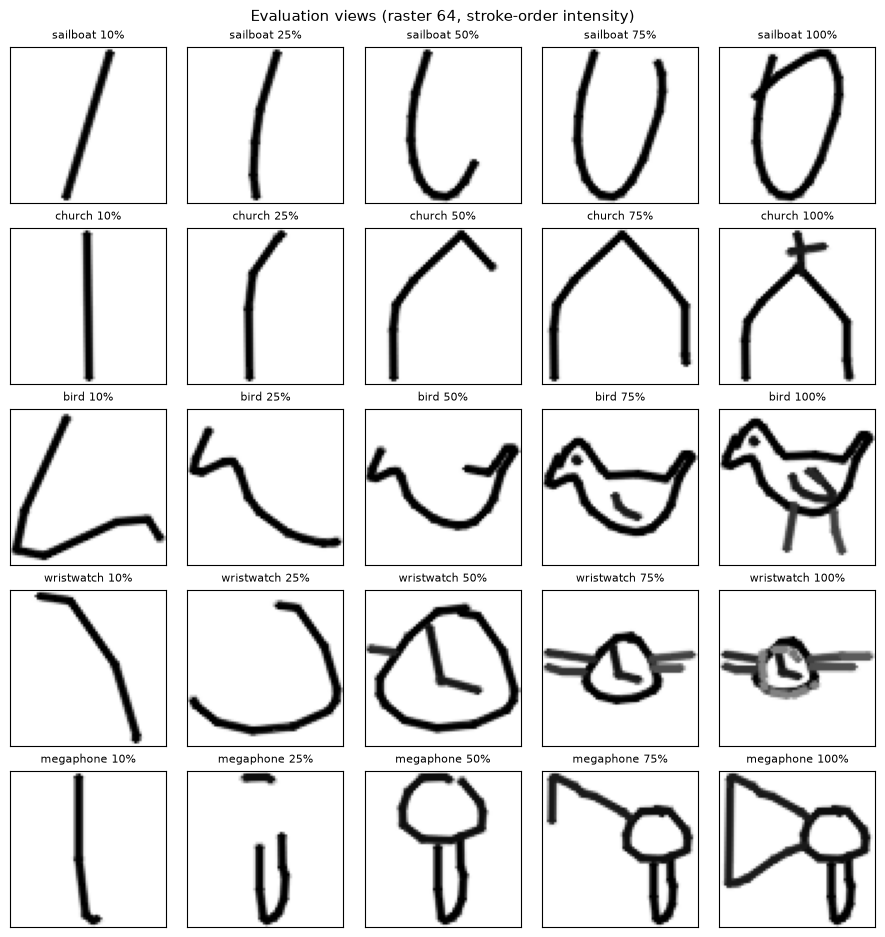

In [6]:
pick = rng.choice(len(val), 5, replace=False)
fig, axes = plt.subplots(5, len(EVAL_FRACS), figsize=(9, 9.5))
for r, i in enumerate(pick):
    for c, f in enumerate(EVAL_FRACS):
        img, _ = RasterView(val, frac=f, order_encoding=True)[i]
        axes[r, c].imshow(img, cmap="gray_r", vmin=0, vmax=255)
        axes[r, c].set(xticks=[], yticks=[])
        axes[r, c].set_title(f"{val.meta['word'].iloc[i]} {int(f * 100)}%", fontsize=8)
fig.suptitle("Evaluation views (raster 64, stroke-order intensity)")
plt.tight_layout()
savefig("eval_fracs")
plt.show()

### Augmentation

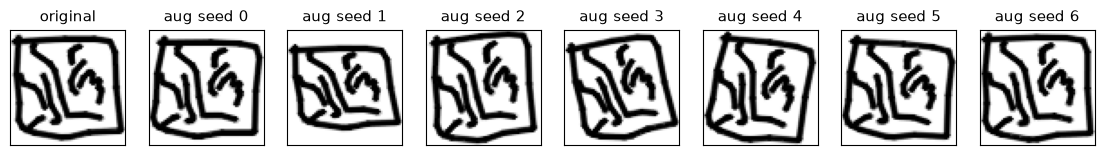

In [7]:
pts, end, _ = ds["train"][int(rng.integers(len(ds["train"])))]
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
axes[0].imshow(rasterize(normalize(pts), end), cmap="gray_r")
axes[0].set(xticks=[], yticks=[], title="original")
for k, ax in enumerate(axes[1:]):
    a = augment(pts, np.random.default_rng(k))
    ax.imshow(rasterize(normalize(a), end), cmap="gray_r")
    ax.set(xticks=[], yticks=[], title=f"aug seed {k}")
savefig("augmentation")
plt.show()

### Giảm mẫu chuỗi dài

Hình dài nhất trong val trước và sau khi đưa về 256 điểm. Đầu/cuối mọi nét được giữ
nên hình dạng tổng thể và số nét không đổi.

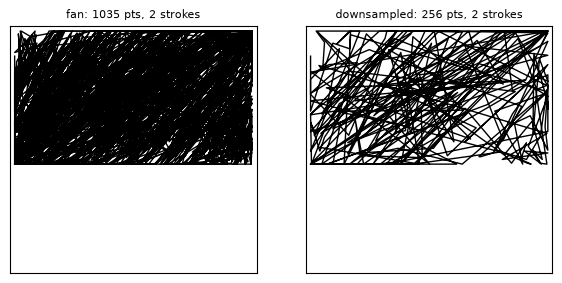

train: 0.1676% hình > 256 điểm; lớp nhiều nhất: {'blackberry': 941, 'camouflage': 584, 'tornado': 372}
val: 0.1683% hình > 256 điểm; lớp nhiều nhất: {'blackberry': 118, 'camouflage': 84, 'tornado': 45}
test: 0.1680% hình > 256 điểm; lớp nhiều nhất: {'blackberry': 85, 'camouflage': 83, 'tornado': 53}


In [8]:
i = int(val.meta["n_points"].idxmax())
pts, end, _ = val[i]
p2, e2 = downsample(pts, end, 256)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
show_xy(axes[0], pts, end, f"{val.meta['word'].iloc[i]}: {len(pts)} pts, {end.sum()} strokes")
show_xy(axes[1], p2, e2, f"downsampled: {len(p2)} pts, {e2.sum()} strokes")
savefig("downsample")
plt.show()
for s, d in ds.items():
    over = d.meta["n_points"] > 256
    print(f"{s}: {over.mean():.4%} hình > 256 điểm; lớp nhiều nhất:",
          d.meta.loc[over, "word"].value_counts().head(3).to_dict())

## 4. Tốc độ nạp dữ liệu (1 tiến trình CPU)

Đo trên 3.000 mẫu train với prefix ngẫu nhiên + augment, như lúc train. Con số giúp ước
lượng cần bao nhiêu worker của `DataLoader` để không nghẽn GPU.

In [9]:
bench = {}
n_bench = 3000
idx = np.random.default_rng(0).choice(len(ds["train"]), n_bench, replace=False)
for name, view in {
    "raw read": ds["train"],
    "raster64 (prefix+aug)": RasterView(ds["train"], frac="random", augment=AugmentConfig()),
    "raster64 order (prefix+aug)": RasterView(ds["train"], frac="random", augment=AugmentConfig(), order_encoding=True),
    "sequence256 (prefix+aug)": SequenceView(ds["train"], frac="random", augment=AugmentConfig()),
    "sequence256 resampled (prefix+aug)": SequenceView(ds["train"], frac="random", augment=AugmentConfig(),
                                                       resample_step=RESAMPLE_STEP),
}.items():
    t = time.perf_counter()
    for j in idx:
        view[int(j)]
    rate = n_bench / (time.perf_counter() - t)
    bench[name] = {"samples_per_s": round(rate), "train_epoch_min_1_core": round(len(ds["train"]) / rate / 60, 1)}
bench = pd.DataFrame(bench).T
bench.to_csv(REPORT_DIR / "loader_throughput.csv")
bench

,samples_per_s,train_epoch_min_1_core
raw read,256476.0,0.2
raster64 (prefix+aug),1959.0,20.4
raster64 order (prefix+aug),5071.0,7.9
sequence256 (prefix+aug),7002.0,5.7
sequence256 resampled (prefix+aug),4068.0,9.8


## 5. Chống rò rỉ dữ liệu (checkpoint của Step 2)

| Nguồn rò rỉ | Cách ngăn |
|---|---|
| Cùng một hình ở nhiều split | Hình giống hệt nhau được chia như một đơn vị; hình trùng khác lớp bị loại. `tests/test_processed_data.py` kiểm tra không có hash nào nằm ở hai split |
| Thống kê fit trên val/test | Thống kê duy nhất là độ lệch chuẩn của dx, dy, fit **chỉ trên train**. Các bước còn lại (chuẩn hoá theo khung, raster) chỉ dùng chính hình đang xử lý |
| Prefix lộ tỉ lệ so với hình hoàn chỉnh | **Chỉ giảm được, chưa chặn hết** (mục 6). Chuẩn hoá theo khung riêng giấu độ lớn; `resample_step` loại lưới toạ độ và mật độ điểm; cạnh gãy vẫn còn trên cả chuỗi và raster. Chỉ cắt trên nét raw rồi simplify mới loại hết. Ghi là giới hạn |
| Chọn checkpoint/siêu tham số trên test | `RasterView`/`SequenceView` không cho phép prefix ngẫu nhiên trên val/test. Val dùng để chọn, test chỉ dùng một lần ở cuối (quy ước của nhóm) |
| Thay đổi split âm thầm | `manifest.json` lưu seed, digest của cách chia và sha256 từng file; test kiểm tra lại |
| Mốc 100% phụ thuộc lúc lượt chơi dừng | **Không ngăn được**: hình recognized có thể dừng ngay khi model của Google nhận ra. Luôn báo cáo tách theo `recognized` |
| Cùng người vẽ ở train và test | **Không ngăn được**: dữ liệu không có user id. Ghi là giới hạn |
| Chọn lớp dựa trên dữ liệu | Việc chọn lớp dùng mẫu 3% của dữ liệu gốc, chỉ dựa trên thống kê hình vẽ, không dựa trên kết quả model nào. Ghi rõ trong báo cáo |

## 6. Rò rỉ tỉ lệ prefix và ý nghĩa của mốc 100%

Đọc kết quả đã đo bởi `scripts/leak_audit.py` và `scripts/raw_pilot.py`. Phân tích đầy đủ và giới
hạn của phép đo nằm trong `reports/preprocessing/leak_audit.md`. Tập test không được dùng.

Nhánh **sạch** cắt prefix trên nét raw rồi mới simplify, nên không chứa thông tin về hình đầy đủ.
Nhánh này chỉ có cho 2 lớp đã tải file raw (*triangle*, *bat*).

In [10]:
audit = json.loads((REPORT_DIR / "leak_audit.json").read_text())
pilot = json.loads((REPORT_DIR / "raw_pilot.json").read_text())
g, c_ = pilot["gb_r2"], pilot["cnn_raster64_r2"]
r2 = pd.DataFrame({
    "100 lớp (val)": {"chuỗi hiện tại": audit["gb_seq_stored"]["r2"],
                     "chuỗi lấy mẫu lại": audit["gb_seq_resampled"]["r2"],
                     "raster 64 hiện tại": audit["cnn_raster64_stored"]["r2"]},
    "pilot 2 lớp": {"chuỗi hiện tại": g["stored"]["all"]["r2"],
                   "chuỗi lấy mẫu lại": g["stored_resampled"]["all"]["r2"],
                   "raster 64 hiện tại": c_["stored"]["r2"]},
    "nhánh sạch cùng loại (pilot)": {"chuỗi hiện tại": g["clean"]["all"]["r2"],
                                    "chuỗi lấy mẫu lại": g["clean_resampled"]["all"]["r2"],
                                    "raster 64 hiện tại": c_["clean"]["r2"]},
})
r2["phần vượt (pilot)"] = r2["pilot 2 lớp"] - r2["nhánh sạch cùng loại (pilot)"]
print("Mức nền của tấn công lưới (luôn đoán tỉ lệ = 1):", round(audit["base_rate_ratio_about_1"], 3))
print("Tấn công lưới, 100 lớp:", {k: round(v, 4) for k, v in audit["grid_attack_hit_rate"].items()})
print("Tấn công lưới, pilot:", {k: round(v, 4) for k, v in pilot["grid_attack_hit_rate"].items()})
r2.round(3)

Mức nền của tấn công lưới (luôn đoán tỉ lệ = 1): 0.337
Tấn công lưới, 100 lớp: {'stored_all': 0.902, 'stored_endpoints': 0.4832, 'resampled_all': 0.0001, 'resampled_endpoints': 0.0008}
Tấn công lưới, pilot: {'stored_all': 0.8471, 'stored_endpoints': 0.3454, 'stored_resampled_all': 0.0001, 'stored_resampled_endpoints': 0.0013, 'clean_all': 0.3317, 'clean_endpoints': 0.2677, 'clean_resampled_all': 0.0001, 'clean_resampled_endpoints': 0.0007}


,100 lớp (val),pilot 2 lớp,nhánh sạch cùng loại (pilot),phần vượt (pilot)
chuỗi hiện tại,0.754,0.789,0.547,0.242
chuỗi lấy mẫu lại,0.529,0.620,0.517,0.102
raster 64 hiện tại,0.501,0.617,0.537,0.081


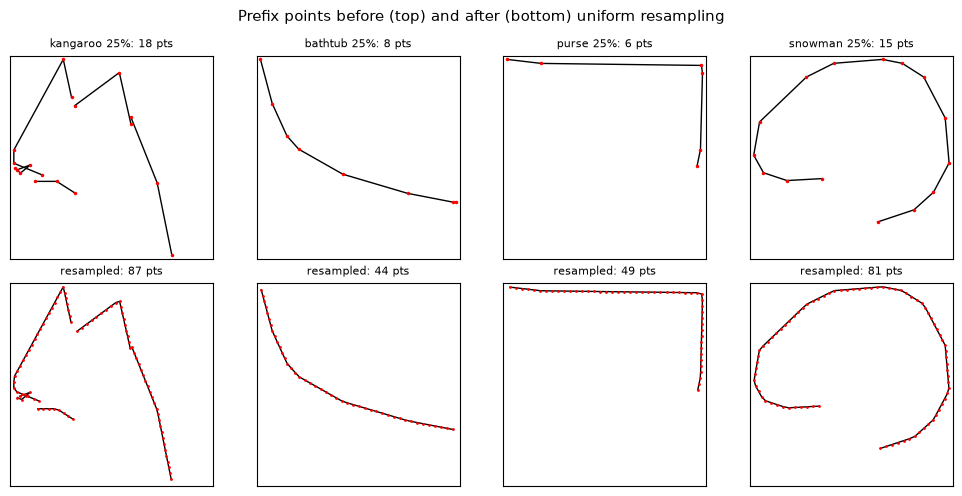

In [11]:
rng2 = np.random.default_rng(SEED)
pick = rng2.choice(len(val), 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k, i in enumerate(pick):
    pts, end, _ = val[i]
    p, e = prefix(pts, end, 0.25)
    n = normalize(p)
    r, re = resample_uniform(n, e, RESAMPLE_STEP)
    show_xy(axes[0, k], n, e, f"{val.meta['word'].iloc[i]} 25%: {len(n)} pts")
    axes[0, k].plot(n[:, 0], n[:, 1], "r.", ms=3)
    show_xy(axes[1, k], r, re, f"resampled: {len(r)} pts")
    axes[1, k].plot(r[:, 0], r[:, 1], "r.", ms=2)
fig.suptitle("Prefix points before (top) and after (bottom) uniform resampling")
plt.tight_layout()
savefig("resample_uniform")
plt.show()

triangle | recognized rate 0.978 | median giây: recognized 1.874 / không 15.685
bat | recognized rate 0.814 | median giây: recognized 9.1465 / không 16.582
Median phần thời gian theo khoảng mực: {'0.05-0.25': 0.11084529505582137, '0.25-0.50': 0.3445823687191168, '0.50-0.75': 0.5675938239458926, '0.75-1.00': 0.8410591780470603} | tương quan mực-thời gian: 0.547


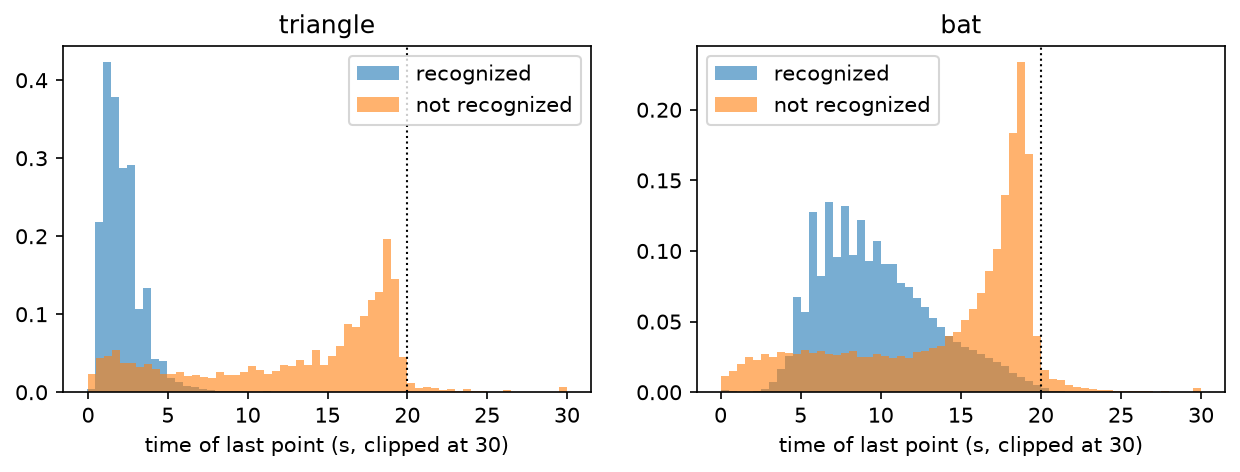

In [12]:
from IPython.display import Image

for w, i in pilot["per_class"].items():
    print(w, "| recognized rate", round(i["recognized_rate_raw"], 3),
          "| median giây: recognized", i["duration_ms_quantiles"]["True"]["0.5"] / 1000,
          "/ không", i["duration_ms_quantiles"]["False"]["0.5"] / 1000)
print("Median phần thời gian theo khoảng mực:", pilot["ink_frac_vs_time_frac"],
      "| tương quan mực-thời gian:", round(pilot["ink_time_corr"], 3))
Image(FIG / "raw_duration_by_recognized.png")

**Nhận xét.**

* Chuỗi hiện tại lộ rõ nhất. Lấy mẫu lại đều loại được lưới toạ độ và mật độ điểm, giảm phần vượt so
  với nhánh sạch từ +0,24 xuống +0,10 (pilot), nhưng chưa hết. Raster 64×64 cũng lộ (+0,08).
* Nhánh sạch vẫn đạt R² 0,52–0,55, tức là phần lớn tỉ lệ suy ra được hợp lệ từ hình dạng.
* R² **không đo** mức tăng ảo độ chính xác phân loại. Câu hỏi đó cần thí nghiệm train model.
* Hình recognized kết thúc sớm hơn hẳn, phù hợp với việc lượt chơi dừng khi được nhận ra, nhưng
  thời điểm nhận ra không được ghi nên đây là bằng chứng gián tiếp, trên 2 lớp.

→ **Quyết định:** kết quả nhận diện sớm trên chuỗi dùng `resample_step=RESAMPLE_STEP`; mặc định vẫn
giữ `None` để so sánh được hai nhánh. Mọi kết quả sớm đều ghi rõ phần rò rỉ còn lại là giới hạn, và
luôn báo cáo tách theo `recognized`.